# 04 — Bayesian analysis

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What this notebook does**

1. Puts priors on the *same* likelihood of notebook 03 (Gaussian whitened bins, sine-Gaussian signal). The two linear amplitudes are marginalised **analytically**;
   the posterior of the three non-linear parameters $(t_0,f_0,Q)$ is evaluated **exactly on a grid** and cross-checked with `emcee` (MCMC).
2. Posterior of the burst parameters and of the SNR, credible intervals, behaviour with SNR and for noise-only data.
3. **Bayes factor** signal against noise: its distribution on real noise, its detection performance against the frequentist statistic of notebook 03,
   and its **dependence on the prior** (Occam factor).
4. **Calibration** of the posterior: simulation-based calibration (rank statistics) and coverage of credible intervals, in ideal Gaussian noise and in real O1 noise.
5. Posterior-predictive (residual) check.
6. **Credible against confidence intervals** for the amplitude at low SNR (frequentist coverage of Bayesian intervals), compared with the profile-likelihood and Neyman/Feldman–Cousins intervals of notebook 03.

**What it does not do**: no new data, no machine learning. The false-alarm numbers are per 1 s window of single-detector data.

Course topics used: Bayes' theorem, priors, marginalisation, credible intervals, MCMC and its diagnostics, Bayes factors and prior dependence (week 4).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, special
import emcee, corner
import gwosc_tools as g
g.style()
rng = np.random.default_rng(404)

CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
v_tr, id_tr, _ = g.load_split("train")
v_te, id_te, _ = g.load_split("test")
S1_te = np.stack([CH[i]["S1"] for i in id_te])
S1c = CH[3]["S1"]
summary = {}

## 1. Model, priors and the exact marginal likelihood

Data in a window: whitened band bins $X_k$. Model $\mathcal M_1$: $X=a\,T(\theta)+n$, $\theta=(t_0,f_0,Q)$, $a=a_c+ia_s\in\mathbb C$, $T$ the unit-norm whitened sine-Gaussian template,
$n_k$ white with unit-variance real and imaginary parts. $\mathcal M_0$: $X=n$.

| parameter | prior |
|---|---|
| $t_0$ | uniform on [0.25, 0.75] s (same as the injections) |
| $f_0$ | log-uniform on [50, 400] Hz |
| $Q$ | uniform on [4, 15] |
| $a_c,a_s$ | $\mathcal N(0,\sigma_\rho^2)$ each, i.e. the SNR $\rho=|a|$ is Rayleigh($\sigma_\rho$); default $\sigma_\rho=10$ |

With $z(\theta)=\sum_kX_kT_k^*e^{2\pi ik t_0}$ and $\rho^2(\theta)=|z|^2$ (the frequentist statistic at fixed $\theta$), the Gaussian integral over $a$ gives

$$\ln\frac{p(X|\theta,\mathcal M_1)}{p(X|\mathcal M_0)}=\frac12\,\frac{\sigma_\rho^2}{1+\sigma_\rho^2}\,\rho^2(\theta)-\ln(1+\sigma_\rho^2),\qquad
a\,|\,\theta,X\sim\mathcal N\!\Big(\tfrac{\sigma_\rho^2}{1+\sigma_\rho^2}z,\ \tfrac{\sigma_\rho^2}{1+\sigma_\rho^2}\Big),$$

so the posterior of $\theta$ and the Bayes factor $B_{10}=\int\pi(\theta)\,[\ldots]\,d\theta$ need only the matched-filter cube $\rho^2(t_0,f_0,Q)$ — the same object as in notebook 03. We check the closed form against a brute-force 2-D integration over $a$.

In [2]:
def template(f0, Q, t0, S1):
    T = 2 * g.sine_gaussian_ft(g.FREQ, f0, Q, 0.0, positive_only=True) * np.exp(-2j*np.pi*g.FREQ*t0) / np.sqrt(S1) * g.BAND
    return T / np.sqrt(np.sum(np.abs(T)**2))

# --- check of the closed form on one injected window, theta fixed at the truth
TR = dict(t0=0.5, f0=150.0, Q=8.0)
p1 = {k: np.array([v]) for k, v in dict(TR, phi=0.7).items()}
ser, _, _ = g.inject(v_te[id_te == 3][:1], "sg", 6.0, rng, S1c, params=p1)
X = g.to_bins(ser)[0]; T = template(TR["f0"], TR["Q"], TR["t0"], S1c)
z = np.sum(X * np.conj(T)); rho2 = abs(z)**2
sig = 10.0
closed = 0.5 * sig**2 / (1 + sig**2) * rho2 - np.log1p(sig**2)
ag = np.linspace(-40, 40, 801); AR, AI = np.meshgrid(ag, ag)
# ln L(a) - ln L(0) = Re(a* z) - |a|^2/2
lnr = (np.conj(AR + 1j*AI) * z).real - 0.5 * (AR**2 + AI**2)
integrand = np.exp(lnr) * np.exp(-(AR**2 + AI**2) / (2 * sig**2)) / (2 * np.pi * sig**2)
brute = np.log(integrand.sum() * (ag[1] - ag[0])**2)
print("ln B(theta_true): closed form %.4f   brute-force integral %.4f" % (closed, brute))
summary["closed_form_check"] = dict(closed=float(closed), brute=float(brute))

ln B(theta_true): closed form 10.7017   brute-force integral 10.7017


## 2. Exact grid posterior

For the posterior we use a finer bank than in notebook 03: 96 log-spaced $f_0$ (2.3 % spacing) × 12 values of $Q$ × all 512 time steps in $t_0\in[0.25,0.75]$ — 590 000 cells.
The prior is uniform on the grid cells by construction. The posterior of the SNR $\rho=|a|$ is the mixture over cells of Rice distributions with
$\nu=|z|\sigma_\rho^2/(1+\sigma_\rho^2)$ and scale $\sigma_\rho^2/(1+\sigma_\rho^2)$.

In [3]:
F0S = np.geomspace(50, 400, 96); QS = np.linspace(4, 15, 12); NF, NQ = len(F0S), len(QS)
TAU_RANGE = (0.25, 0.75)
FB = {i: g.SGBank(CH[i]["S1"], f0s=F0S, Qs=QS) for i in (3, 7)}
RHO = np.linspace(0, 45, 451)

def grid_posterior(cube, sigma=10.0):
    # cube: (b, NQ*NF, nt) of rho^2  ->  marginals and ln Bayes factor
    b = cube.shape[0]; c = cube.reshape(b, NQ, NF, -1).astype(np.float64)
    s2 = sigma**2; lnl = 0.5 * c * s2 / (1 + s2) - np.log1p(s2)
    m = lnl.max(axis=(1, 2, 3), keepdims=True); w = np.exp(lnl - m); Z = w.sum(axis=(1, 2, 3))
    lnBF = m[:, 0, 0, 0] + np.log(Z / w[0].size); w /= Z[:, None, None, None]
    return dict(lnBF=lnBF, w=w, c=c, p_t=w.sum((1, 2)), p_f=w.sum((1, 3)), p_Q=w.sum((2, 3)))

def snr_posterior(w, c, sigma=10.0, nbin=400):
    # mixture of Rice densities over the cells. The density depends on a cell only through nu = |z| sigma^2/(1+sigma^2),
    # so the cell weights are first histogrammed in nu (exact up to the bin width 0.1)
    s2 = sigma**2; sg2 = s2 / (1 + s2); out = np.zeros((len(w), len(RHO)))
    edges = np.linspace(0, 50, nbin + 1); mid = 0.5 * (edges[1:] + edges[:-1])
    for n in range(len(w)):
        nu = np.sqrt(c[n]).ravel() * sg2
        wt, _ = np.histogram(nu, bins=edges, weights=w[n].ravel())
        m = wt > 1e-12 * wt.max(); nu_m, wt_m = mid[m], wt[m]
        arg = RHO[None, :] * nu_m[:, None] / sg2
        dens = RHO[None, :] / sg2 * special.i0e(arg) * np.exp(arg - (RHO[None, :]**2 + nu_m[:, None]**2) / (2 * sg2))
        out[n] = (wt_m[:, None] * dens).sum(0)
    return out / (out.sum(1, keepdims=True) * (RHO[1] - RHO[0]))

def interval(x, p, level=0.68, hpd=False):
    p = p / p.sum()
    if not hpd:
        c = np.cumsum(p); a = (1 - level) / 2
        return x[np.searchsorted(c, a)], x[min(np.searchsorted(c, 1 - a), len(x) - 1)]
    o = np.argsort(-p); k = np.searchsorted(np.cumsum(p[o]), level) + 1
    return x[o[:k]].min(), x[o[:k]].max()

def pit(x, p, true, u):
    # randomised probability-integral transform of the truth in a discrete posterior (uniform inside the cell)
    p = p / p.sum(); c = np.cumsum(p); i = np.clip(np.argmin(np.abs(x - true)), 0, len(x) - 1)
    return (c[i] - p[i]) + u * p[i]

def posterior_of(series, chunk=3, sigma=10.0, with_snr=True):
    X = g.to_bins(series)
    o = FB[chunk].scan(X, tau_range=TAU_RANGE, batch=16, return_cube=True)
    P = grid_posterior(o["cube"], sigma); P["taus"] = o["taus"]
    if with_snr: P["p_rho"] = snr_posterior(P["w"], P["c"], sigma)
    return P

### Posterior of one burst at increasing SNR

Same noise window and same sine-Gaussian ($t_0=0.5$ s, $f_0=150$ Hz, $Q=8$), injected at ρ = 5, 8, 12, 20; plus the noise-only window.

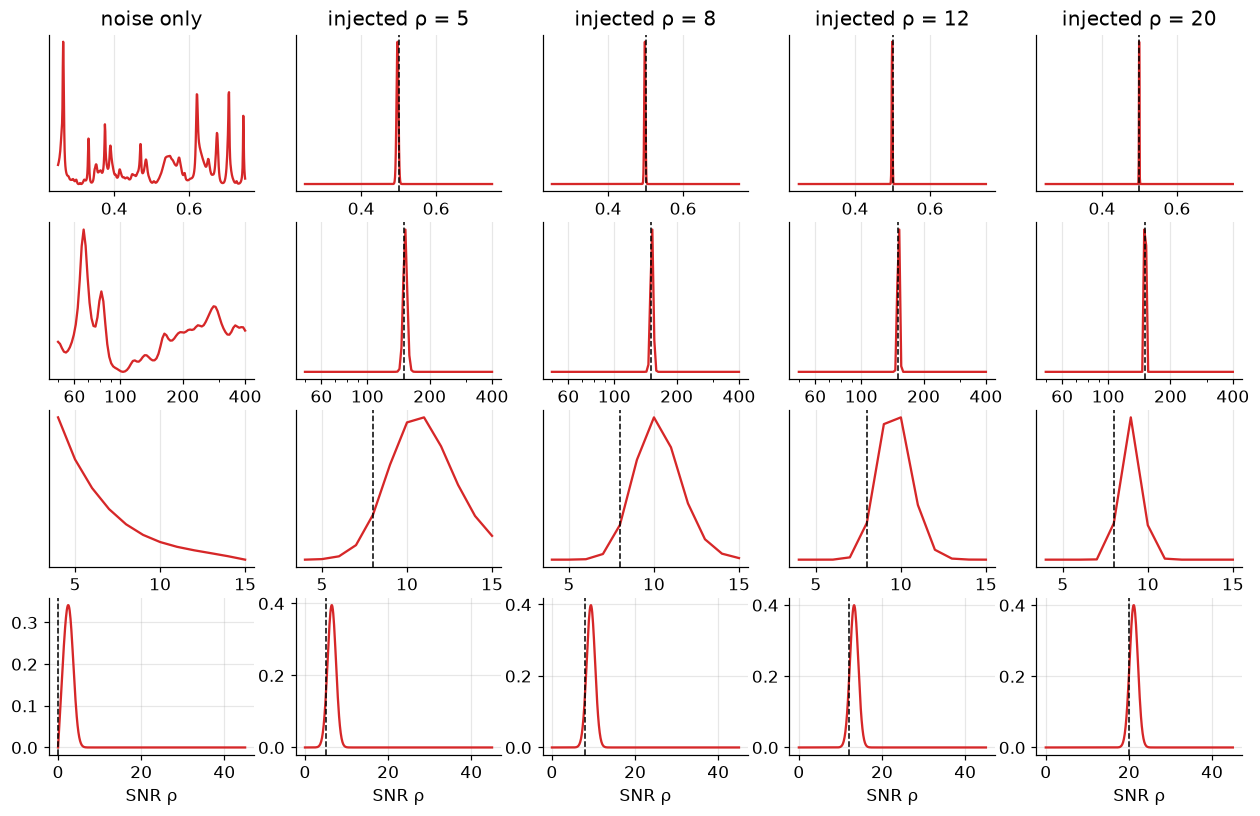

In [4]:
k = 1234
noise_w = v_te[id_te == 3][k:k+1]
SNRS_EX = [0, 5, 8, 12, 20]
posts = {}
for snr in SNRS_EX:
    ser = noise_w if snr == 0 else g.inject(noise_w, "sg", float(snr), rng, S1c, params={kk: np.array([vv]) for kk, vv in dict(TR, phi=0.7).items()})[0]
    posts[snr] = posterior_of(ser)

fig, ax = plt.subplots(4, len(SNRS_EX), figsize=(14, 8.5))
tx = posts[5]["taus"]
for j, snr in enumerate(SNRS_EX):
    P = posts[snr]
    for r, (key, x, true, lab) in enumerate([("p_t", tx, TR["t0"], "$t_0$ [s]"), ("p_f", F0S, TR["f0"], "$f_0$ [Hz]"), ("p_Q", QS, TR["Q"], "$Q$")]):
        a = ax[r, j]; a.plot(x, P[key][0], color=g.COLORS["bayes"])
        if snr > 0: a.axvline(true, color="k", ls="--", lw=1)
        a.set_xlabel(lab); a.set_yticks([])
        if r == 1:
            a.set_xscale("log"); a.set_xticks([60, 100, 200, 400]); a.set_xticklabels(["60", "100", "200", "400"]); a.xaxis.set_minor_formatter(plt.NullFormatter())
    ax[3, j].plot(RHO, P["p_rho"][0], color=g.COLORS["bayes"]); ax[3, j].axvline(snr, color="k", ls="--", lw=1); ax[3, j].set_xlabel("SNR ρ")
    ax[0, j].set_title(f"injected ρ = {snr}" if snr else "noise only")
g.savefig(fig, "fig04_posteriors"); plt.show()

In [5]:
rows = []
for snr in SNRS_EX[1:]:
    P = posts[snr]; r_ = {"snr": snr, "lnBF": float(P["lnBF"][0])}
    for key, x, nm, true in [("p_t", tx, "t0", TR["t0"]), ("p_f", F0S, "f0", TR["f0"]), ("p_Q", QS, "Q", TR["Q"])]:
        lo, hi = interval(x, P[key][0]); r_[nm + "_68"] = f"[{lo:.3g}, {hi:.3g}]"; r_[nm + "_mean"] = float(np.sum(x * P[key][0]) / P[key][0].sum())
    lo, hi = interval(RHO, P["p_rho"][0], hpd=True); r_["rho_HPD68"] = f"[{lo:.1f}, {hi:.1f}]"; r_["rho_mean"] = float(np.sum(RHO * P["p_rho"][0]) / P["p_rho"][0].sum())
    rows.append(r_)
pd.DataFrame(rows)

,snr,lnBF,t0_68,t0_mean,f0_68,f0_mean,Q_68,Q_mean,rho_HPD68,rho_mean
0,5,8.462206,"[0.494, 0.499]",0.496698,"[149, 156]",152.369512,"[9, 13]",10.923839,"[5.4, 7.4]",6.442131
1,8,30.674859,"[0.496, 0.5]",0.497959,"[149, 153]",151.902326,"[9, 12]",10.270526,"[8.4, 10.3]",9.368772
2,12,74.523272,"[0.498, 0.5]",0.498724,"[149, 153]",151.513171,"[9, 11]",9.639066,"[12.3, 14.2]",13.291063
3,20,210.241557,"[0.499, 0.5]",0.499324,"[149, 153]",150.929015,"[8, 10]",8.998165,"[20.2, 22.1]",21.157457


At ρ = 5 the posterior of $(f_0,Q)$ is broad and the SNR posterior is wide and pulled by the prior; at ρ ≥ 12 the posteriors collapse around the truth
(notebook 03's Fisher bound is the Gaussian limit of these). The noise-only window gives a nearly flat $t_0$ posterior and an SNR posterior piled up at small ρ —
the *prior* speaking, with the Bayes factor close to or below 1.

## 3. Cross-check with MCMC (`emcee`)

Five parameters $(t_0,f_0,Q,\mathrm{Re}\,a,\mathrm{Im}\,a)$, 40 walkers, 6000 steps, no marginalisation — an independent computation of the same posterior.

In [6]:
def log_post(th, X, S1, sigma=10.0):
    t0, f0, Q, ar, ai = th
    if not (0.25 < t0 < 0.75 and 50 < f0 < 400 and 4 < Q < 15): return -np.inf
    a = ar + 1j * ai
    return -0.5 * np.sum(np.abs(X - a * template(f0, Q, t0, S1))**2) - 0.5 * (ar**2 + ai**2) / sigma**2 - np.log(f0)

mc = {}
t0_ = time.time()
for snr in (8, 12, 20):
    ser = g.inject(noise_w, "sg", float(snr), rng, S1c, params={kk: np.array([vv]) for kk, vv in dict(TR, phi=0.7).items()})[0]
    X = g.to_bins(ser)[0]
    P = posts[snr]                                              # same injection phases/noise as the grid run? -> recompute grid for this very data
    Pg = posterior_of(ser)
    j = np.unravel_index(Pg["w"][0].argmax(), Pg["w"][0].shape)
    x0 = np.array([Pg["taus"][j[2]], F0S[j[1]], QS[j[0]], snr * np.cos(.7), snr * np.sin(.7)])
    nw = 40; p0 = x0 + 1e-3 * rng.normal(size=(nw, 5)) * np.array([.01, 20, 2, 1, 1]) * 10
    s = emcee.EnsembleSampler(nw, 5, log_post, args=(X, S1c)); s.run_mcmc(p0, 6000, progress=False)
    ch = s.get_chain(discard=2000, flat=True)
    tau = s.get_autocorr_time(tol=0, discard=2000)
    mc[snr] = dict(chain=ch, tau=tau, acc=float(np.mean(s.acceptance_fraction)), grid=Pg)
print("emcee time %.0f s" % (time.time() - t0_))
rows = []
for snr, d in mc.items():
    ch, Pg = d["chain"], d["grid"]
    for nm, col, x, key in (("t0", 0, tx, "p_t"), ("f0", 1, F0S, "p_f"), ("Q", 2, QS, "p_Q")):
        pg = Pg[key][0] / Pg[key][0].sum()
        mg = np.sum(x * pg); sg = np.sqrt(np.sum((x - mg)**2 * pg))
        rows.append(dict(snr=snr, par=nm, mean_grid=mg, mean_mcmc=ch[:, col].mean(), std_grid=sg, std_mcmc=ch[:, col].std(),
                         max_tau=float(np.max(d["tau"])), accept=d["acc"], eff_samples=len(ch) / np.max(d["tau"])))
mcmc_tab = pd.DataFrame(rows); mcmc_tab

emcee time 39 s


,snr,par,mean_grid,mean_mcmc,std_grid,std_mcmc,max_tau,accept,eff_samples
0,8,t0,0.497959,0.497768,0.001664,0.001544,297.871646,0.307671,537.144109
1,8,f0,151.902326,152.037189,2.367253,2.326112,297.871646,0.307671,537.144109
2,8,Q,10.270526,10.258315,1.383858,1.355400,297.871646,0.307671,537.144109
3,12,t0,0.498724,0.498654,0.001100,0.000962,247.521070,0.353317,646.409617
4,12,f0,151.513171,151.499241,1.783556,1.709365,247.521070,0.353317,646.409617
5,12,Q,9.639066,9.660730,0.968911,0.953645,247.521070,0.353317,646.409617
6,20,t0,0.499324,0.499309,0.000647,0.000623,214.985447,0.393800,744.236423
7,20,f0,150.929015,150.919159,1.651905,1.149291,214.985447,0.393800,744.236423
8,20,Q,8.998165,9.036756,0.595399,0.599430,214.985447,0.393800,744.236423


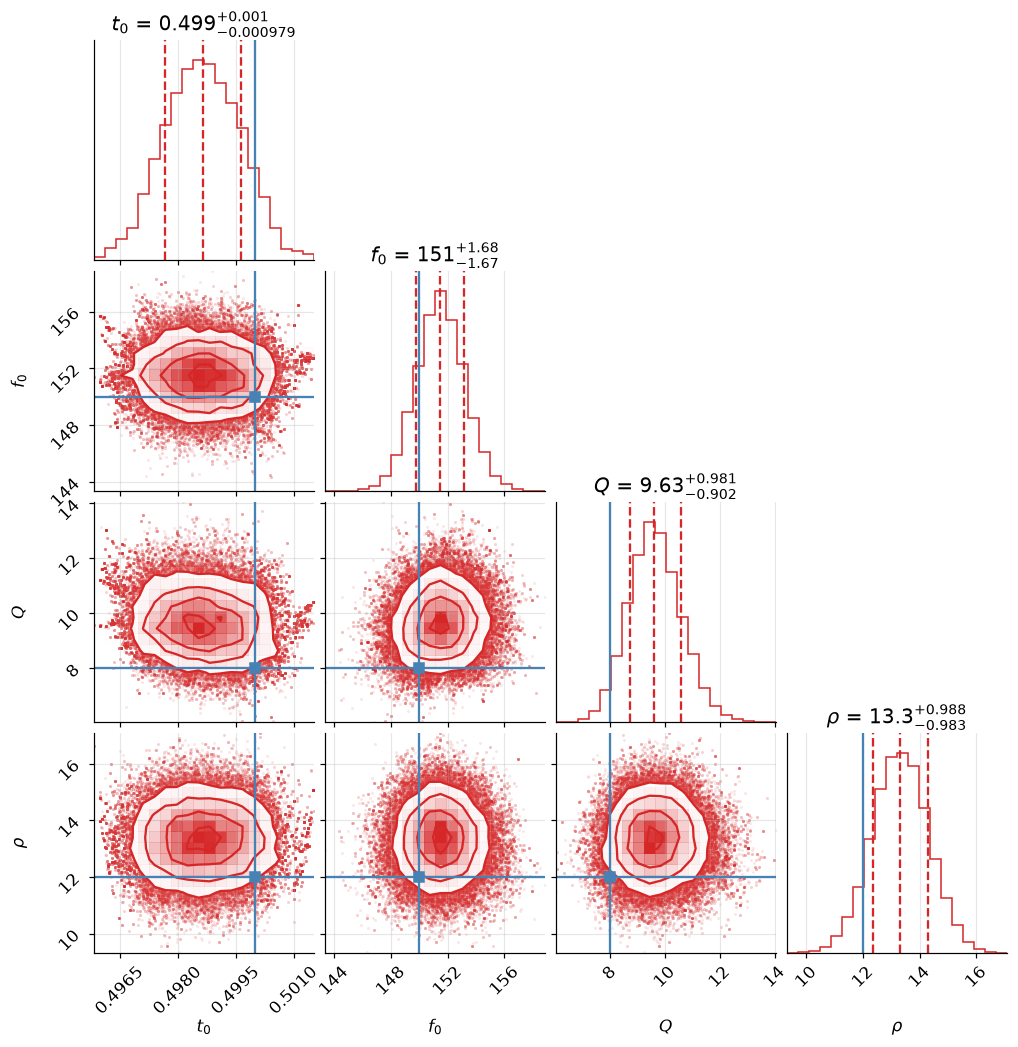

In [7]:
d = mc[12]; ch = d["chain"]
rho_ch = np.hypot(ch[:, 3], ch[:, 4])
fig = corner.corner(np.column_stack([ch[:, :3], rho_ch]), labels=[r"$t_0$", r"$f_0$", r"$Q$", r"$\rho$"], truths=[TR["t0"], TR["f0"], TR["Q"], 12],
                    color=g.COLORS["bayes"], show_titles=True, title_fmt=".3g", quantiles=[.16, .5, .84])
g.savefig(fig, "fig04_corner_snr12"); plt.show()

Grid and MCMC agree on means and widths (same priors, same likelihood): the exact grid is validated and, conversely, the MCMC is validated by a computation
that cannot be stuck in a mode. The integrated autocorrelation time is 260–380 steps (acceptance 0.32–0.38), i.e. 420–610 effective samples from 160 000 retained draws, ample for means and widths. One difference is informative: at ρ = 20 the grid width of $f_0$ is 1.65 Hz against 1.14 Hz from MCMC, because the posterior is narrower than the grid cell (2.3 % ≈ 3.4 Hz); the grid is the limiting factor at high SNR.
The corner plot shows the physical structure of the posterior: $f_0$ and $Q$ are correlated (the product $f_0$/Q sets the bandwidth, which the data constrain better than each parameter).

## 4. Bayes factors

### The Bayes factor as a detection statistic

We compute $\ln B_{10}$ with the nominal 160-template bank of notebook 03 (so that the *only* difference with the frequentist statistic is how the cells are combined:
max over cells versus prior-weighted average) on the same real background and the same injections.

scan time 0 s


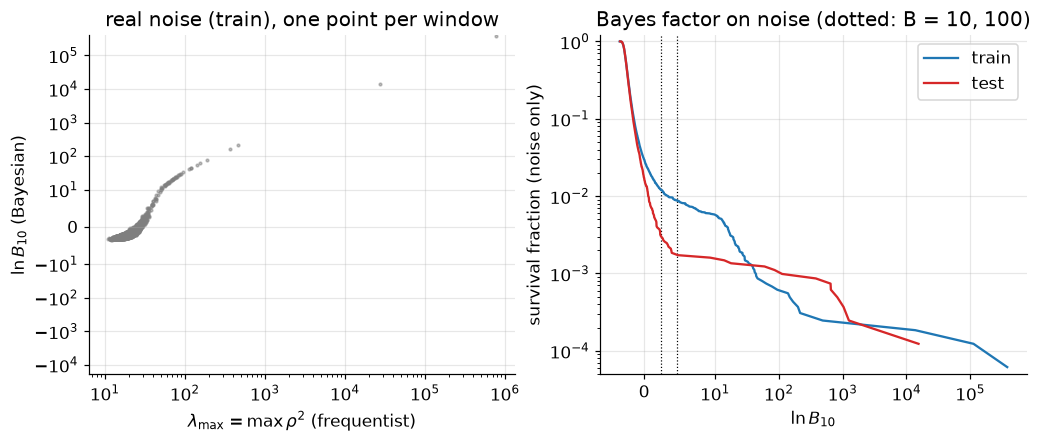

{'B>1': {'train': 0.029647435897435896, 'test': 0.016518737672583828}, 'B>10': {'train': 0.012142504930966469, 'test': 0.003081854043392505}, 'B>100': {'train': 0.008814102564102564, 'test': 0.0017258382642998027}}
Spearman(lambda_max, lnBF) on train noise: 0.823


In [8]:
banks = {i: g.SGBank(CH[i]["S1"]) for i in CH}
SIG0 = 10.0
def cached(name, v, cid):
    fn = os.path.join(g.CACHE, f"scan04_{name}.npz")
    if os.path.exists(fn):
        d = np.load(fn); return {k: d[k] for k in d.files}
    o = g.scan_mixed(v, cid, banks, sigma_prior=SIG0); np.savez_compressed(fn, **o); return o
t0_ = time.time(); btr = cached("train", v_tr, id_tr); bte = cached("test", v_te, id_te); print("scan time %.0f s" % (time.time() - t0_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(btr["rho2"][::2], btr["lnBF"][::2], s=3, color=g.COLORS["grey"], alpha=.5)
ax[0].set_xscale("log"); ax[0].set_yscale("symlog", linthresh=10)
ax[0].set_xlabel(r"$\lambda_{\max}=\max\rho^2$ (frequentist)"); ax[0].set_ylabel(r"$\ln B_{10}$ (Bayesian)"); ax[0].set_title("real noise (train), one point per window")
for thr in (np.log(10), np.log(100)): ax[1].axvline(thr, color="k", ls=":", lw=.8)
for name, b, c in (("train", btr, g.COLORS["freq"]), ("test", bte, g.COLORS["bayes"])):
    xs = np.sort(b["lnBF"]); ax[1].semilogy(xs, 1 - np.arange(len(xs)) / len(xs), color=c, label=name)
ax[1].set_xscale("symlog", linthresh=10); ax[1].set_xlabel(r"$\ln B_{10}$"); ax[1].set_ylabel("survival fraction (noise only)"); ax[1].set_ylim(5e-5, 1.2); ax[1].legend(); ax[1].set_title("Bayes factor on noise (dotted: B = 10, 100)")
g.savefig(fig, "fig04_bf_noise"); plt.show()
fa = {f"B>{t}": {"train": float((btr["lnBF"] > np.log(t)).mean()), "test": float((bte["lnBF"] > np.log(t)).mean())} for t in (1, 10, 100)}
print(fa); summary["noise_false_evidence"] = fa
print("Spearman(lambda_max, lnBF) on train noise: %.3f" % stats.spearmanr(btr["rho2"], btr["lnBF"]).correlation)

Even with a prior that spreads the SNR up to ~20, a non-negligible fraction of **pure-noise** windows reaches a Bayes factor above 10 (“strong” on the Jeffreys scale) and some above 100 (“decisive”).
The reason is the same as in notebook 03: the Bayes factor assumes Gaussian noise, and a glitch is evidence for *something* that the model can only call a burst. The Jeffreys scale is a scale of
evidence **within the model**; it is not a false-alarm probability — which has to be calibrated on background, exactly as for the frequentist statistic.

### Detection performance: $\lambda_{\max}$ against $\ln B_{10}$

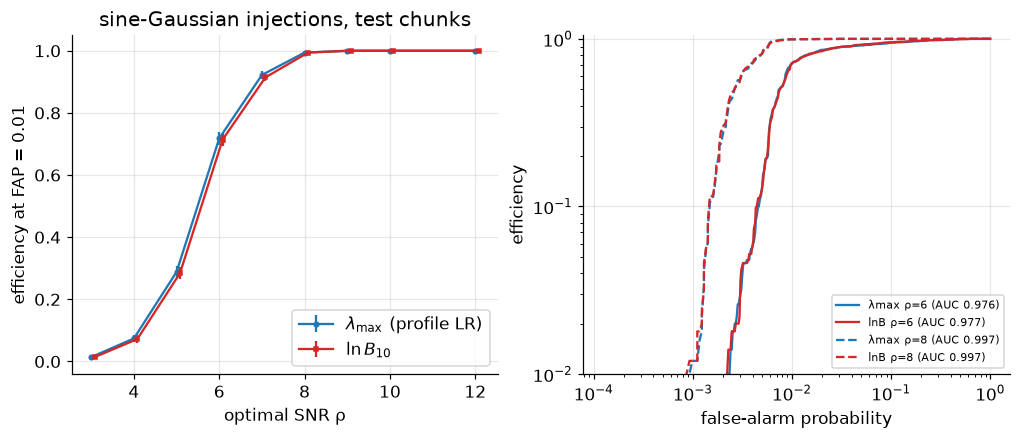

In [9]:
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12]
inj = {}
for snr in SNRS:
    idx = rng.choice(len(v_te), 500, replace=False)
    ser, p, _ = g.inject(v_te[idx], "sg", float(snr), rng, S1_te[idx])
    inj[snr] = g.scan_mixed(ser, id_te[idx], banks, sigma_prior=SIG0)
far = 1e-2
thr_f = g.threshold_at_far(btr["rho2"], far); thr_b = g.threshold_at_far(btr["lnBF"], far)
ef = np.array([g.efficiency(inj[s]["rho2"], thr_f) for s in SNRS]); eb = np.array([g.efficiency(inj[s]["lnBF"], thr_b) for s in SNRS])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(SNRS, ef[:, 0], ef[:, 1], marker="o", ms=3, color=g.COLORS["freq"], label=r"$\lambda_{\max}$ (profile LR)")
ax[0].errorbar(np.array(SNRS) + .08, eb[:, 0], eb[:, 1], marker="s", ms=3, color=g.COLORS["bayes"], label=r"$\ln B_{10}$")
ax[0].set_xlabel("optimal SNR ρ"); ax[0].set_ylabel(f"efficiency at FAP = {far:g}"); ax[0].legend(); ax[0].set_title("sine-Gaussian injections, test chunks")
for snr, ls in ((6, "-"), (8, "--")):
    fa_, ea_ = g.roc(btr["rho2"], inj[snr]["rho2"]); ax[1].loglog(fa_, np.maximum(ea_, 1e-3), ls=ls, color=g.COLORS["freq"], label=f"λmax ρ={snr} (AUC {g.auc(btr['rho2'], inj[snr]['rho2']):.3f})")
    fb_, eb_ = g.roc(btr["lnBF"], inj[snr]["lnBF"]); ax[1].loglog(fb_, np.maximum(eb_, 1e-3), ls=ls, color=g.COLORS["bayes"], label=f"lnB ρ={snr} (AUC {g.auc(btr['lnBF'], inj[snr]['lnBF']):.3f})")
ax[1].set_xlabel("false-alarm probability"); ax[1].set_ylabel("efficiency"); ax[1].legend(fontsize=7.5); ax[1].set_ylim(1e-2, 1.05)
g.savefig(fig, "fig04_bf_vs_freq"); plt.show()
summary["bf_vs_freq"] = dict(snr=SNRS, eff_lambda=ef[:, 0].tolist(), eff_lnBF=eb[:, 0].tolist(),
                             auc_lambda={s: g.auc(btr["rho2"], inj[s]["rho2"]) for s in (6, 8)}, auc_lnBF={s: g.auc(btr["lnBF"], inj[s]["lnBF"]) for s in (6, 8)})

At equal false-alarm probability the two statistics detect essentially the same bursts: the ranking is almost identical (high Spearman correlation on noise), the difference being the
prior weighting of the cells instead of the maximum. The Bayesian machinery's advantage is not detection power but what comes with it — a posterior for the parameters and a
coherent way to include the prior.

### Dependence on the prior (Occam factor)

For the same data the Bayes factor depends on the prior width $\sigma_\rho$ of the SNR and on the time-prior range; the posterior of the SNR depends on $\sigma_\rho$ only through the prior pull at low SNR.

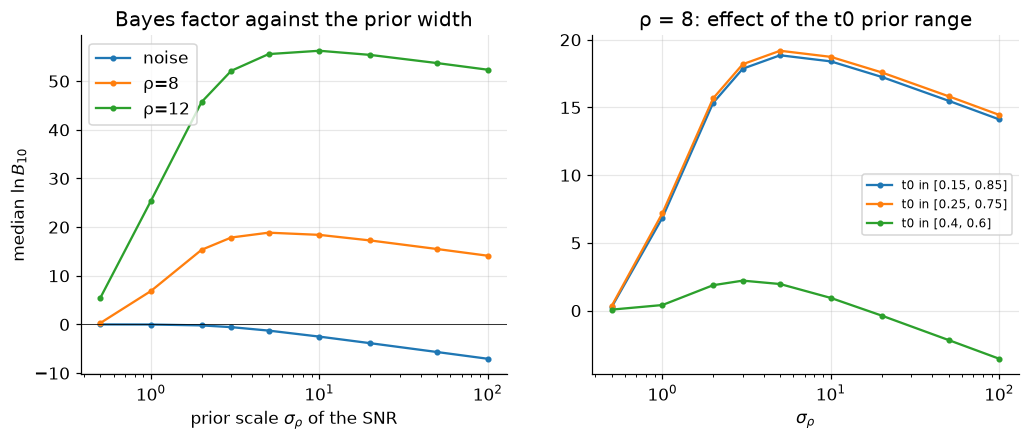

,noise,ρ=8,ρ=12
0.5,-0.003296,0.265740,5.413951
1.0,-0.021831,6.858382,25.385391
2.0,-0.206666,15.332443,45.698900
3.0,-0.562664,17.858006,52.114958
5.0,-1.272576,18.850729,55.551272
10.0,-2.508319,18.399810,56.233993
20.0,-3.854983,17.256150,55.384299
50.0,-5.675492,15.492162,53.703407
100.0,-7.060078,14.115690,52.338835


In [10]:
# 300 noise windows and 300 sine-Gaussian injections at rho = 8 and 12, cube on the nominal bank
def cubes(series, cid):
    out = []
    for c in np.unique(cid):
        o = banks[c].scan(g.to_bins(series[cid == c]), return_cube=True); out.append(o["cube"]); taus = o["taus"]
    return np.concatenate(out), taus
ii = rng.choice(len(v_te), 300, replace=False)
sets = {"noise": v_te[ii]}
for s in (8, 12): sets[f"ρ={s}"] = g.inject(v_te[ii], "sg", float(s), rng, S1_te[ii])[0]
cb = {k: cubes(v, id_te[ii]) for k, v in sets.items()}
def lnBF_from(cube, sigma, taus, trange=(0.15, 0.85)):
    m = (taus >= trange[0]) & (taus <= trange[1]); c = cube[..., m].reshape(len(cube), -1).astype(np.float64)
    s2 = sigma**2; l = 0.5 * c * s2 / (1 + s2) - np.log1p(s2); mm = l.max(1)
    return mm + np.log(np.mean(np.exp(l - mm[:, None]), axis=1))
SIGS = [0.5, 1, 2, 3, 5, 10, 20, 50, 100]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tab = {}
for k, (cube, taus) in cb.items():
    mean = [np.median(lnBF_from(cube, s, taus)) for s in SIGS]; tab[k] = mean
    ax[0].semilogx(SIGS, mean, marker="o", ms=3, label=k)
ax[0].axhline(0, color="k", lw=.5); ax[0].set_xlabel(r"prior scale $\sigma_\rho$ of the SNR"); ax[0].set_ylabel(r"median $\ln B_{10}$"); ax[0].legend(); ax[0].set_title("Bayes factor against the prior width")
cube8, taus = cb["ρ=8"]
for lab, tr_ in (("t0 in [0.15, 0.85]", (0.15, 0.85)), ("t0 in [0.25, 0.75]", (0.25, 0.75)), ("t0 in [0.4, 0.6]", (0.4, 0.6))):
    ax[1].semilogx(SIGS, [np.median(lnBF_from(cube8, s, taus, tr_)) for s in SIGS], marker="o", ms=3, label=lab)
ax[1].set_xlabel(r"$\sigma_\rho$"); ax[1].set_title("ρ = 8: effect of the t0 prior range"); ax[1].legend(fontsize=8)
g.savefig(fig, "fig04_prior_dependence"); plt.show()
summary["prior_dependence_median_lnBF"] = dict(sigma=SIGS, **tab)
pd.DataFrame(tab, index=SIGS)

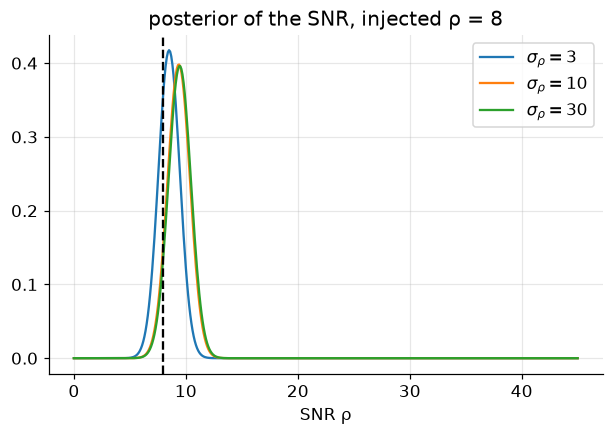

,sigma,mean,hpd68,lnBF
0,3,8.505246,"[7.6, 9.4]",29.006107
1,10,9.368772,"[8.4, 10.3]",30.674859
2,30,9.452771,"[8.5, 10.5]",28.875706


In [11]:
# prior dependence of the SNR posterior for the injected ρ = 8 window of section 2
ser8 = g.inject(noise_w, "sg", 8.0, np.random.default_rng(5), S1c, params={kk: np.array([vv]) for kk, vv in dict(TR, phi=0.7).items()})[0]
fig, ax = plt.subplots(figsize=(6.5, 4))
rows = []
for s in (3, 10, 30):
    P = posterior_of(ser8, sigma=float(s)); ax.plot(RHO, P["p_rho"][0], label=rf"$\sigma_\rho={s}$")
    lo, hi = interval(RHO, P["p_rho"][0], hpd=True); rows.append(dict(sigma=s, mean=float(np.sum(RHO * P["p_rho"][0]) / P["p_rho"][0].sum()), hpd68=f"[{lo:.1f}, {hi:.1f}]", lnBF=float(P["lnBF"][0])))
ax.axvline(8, color="k", ls="--"); ax.set_xlabel("SNR ρ"); ax.legend(); ax.set_title("posterior of the SNR, injected ρ = 8")
g.savefig(fig, "fig04_snr_prior"); plt.show(); pd.DataFrame(rows)

The Bayes factor falls like $-2\ln\sigma_\rho$ at large prior width (two amplitude components: the penalty of ln(1+σ²) in the closed form) — the Occam penalty for a prior that wastes mass on SNRs the data exclude. For noise it decreases monotonically (from 0 at σ → 0 to −7 at σ = 100: the evidence *for the null* grows as the alternative is diluted), and for a signal it has a maximum at σ_ρ of the order of the true SNR (σ ≈ 5 for ρ = 8, ≈ 10 for ρ = 12). The time-prior range changes it by $\ln$(range ratio), as expected from the volume factor. Whenever a Bayes factor is quoted, the prior has to be quoted with it.
The SNR posterior at ρ = 8 moves by a fraction of its width over a factor of 10 in $\sigma_\rho$: the data dominate at this SNR; at ρ ≈ 3–4 the prior would dominate.

## 5. Calibration of the posterior (simulation-based calibration)

If the model is right, drawing the truth from the prior, simulating data and computing the posterior CDF of the truth, the result is uniform. We draw $\theta$ and $\rho$ from the prior of section 1,
inject into (a) ideal Gaussian noise and (b) **real** test windows, and compute the randomised PIT of $t_0$, $f_0$, $Q$ and $\rho$. 500 + 500 simulations.

SBC time 86 s


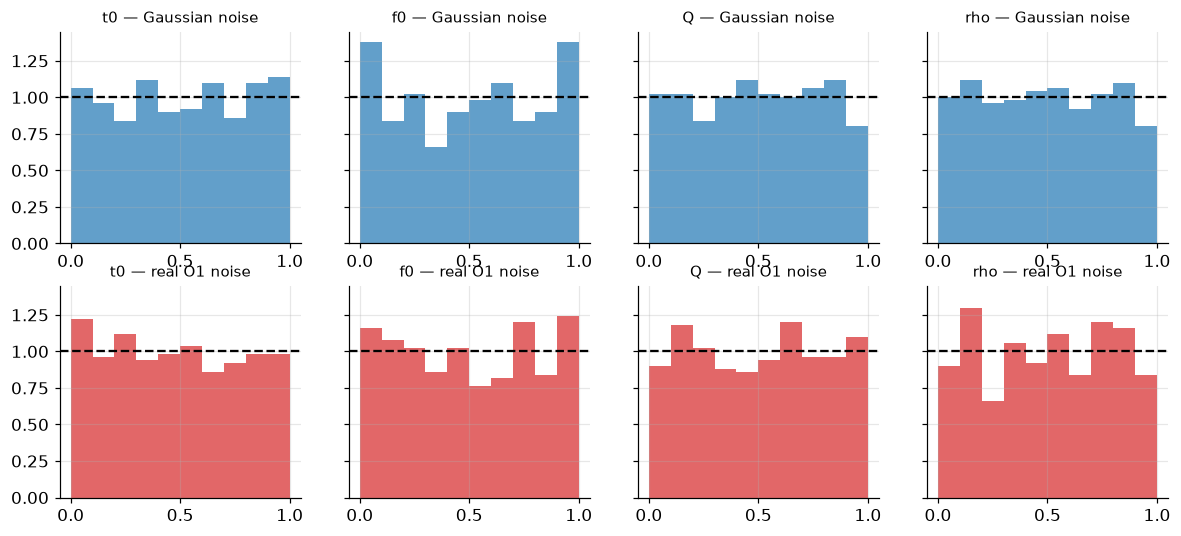

,noise,par,ks_p,cov68
0,Gaussian noise,t0,0.712090,0.604
1,Gaussian noise,f0,0.239957,0.504
2,Gaussian noise,Q,0.903232,0.656
3,Gaussian noise,rho,0.791285,0.688
4,real O1 noise,t0,0.248468,0.576
5,real O1 noise,f0,0.595198,0.514
6,real O1 noise,Q,0.792461,0.646
7,real O1 noise,rho,0.854191,0.668


In [12]:
def sbc(real, n=500, sigma=10.0):
    pits = {k: [] for k in ("t0", "f0", "Q", "rho")}; cov = {k: [] for k in pits}; widths = {k: [] for k in pits}; rhos = []
    for chunk, nn in ((3, n // 2), (7, n - n // 2)):
        S1 = CH[chunk]["S1"]
        if real: base = v_te[id_te == chunk][rng.choice((id_te == chunk).sum(), nn, replace=False)]
        else: base = g.to_series((rng.normal(size=(nn, g.NB)) + 1j * rng.normal(size=(nn, g.NB))) * g.BAND)
        p = g.draw_params("sg", rng, nn); rho = np.hypot(rng.normal(0, sigma, nn), rng.normal(0, sigma, nn)); rhos.append(rho)
        ser, _, _ = g.inject(base, "sg", rho, rng, S1, params=p)
        P = posterior_of(ser, chunk=chunk, sigma=sigma)
        for n_ in range(nn):
            for key, x, nm, true in (("p_t", tx, "t0", p["t0"][n_]), ("p_f", F0S, "f0", p["f0"][n_]), ("p_Q", QS, "Q", p["Q"][n_]), ("p_rho", RHO, "rho", rho[n_])):
                pm = P[key][n_]; u = pit(x, pm, true, rng.uniform())
                pits[nm].append(u); lo, hi = interval(x, pm, 0.68); cov[nm].append(lo <= true <= hi); widths[nm].append(hi - lo)
    return {k: np.array(v) for k, v in pits.items()}, {k: np.mean(v) for k, v in cov.items()}
t0_ = time.time()
pit_g, cov_g = sbc(False); pit_r, cov_r = sbc(True)
print("SBC time %.0f s" % (time.time() - t0_))
fig, ax = plt.subplots(2, 4, figsize=(13, 5.5), sharey=True)
rows = []
for r, (pits, lab) in enumerate(((pit_g, "Gaussian noise"), (pit_r, "real O1 noise"))):
    for c, nm in enumerate(("t0", "f0", "Q", "rho")):
        ax[r, c].hist(pits[nm], bins=10, range=(0, 1), density=True, color=g.COLORS["bayes"] if r else g.COLORS["freq"], alpha=.7)
        ax[r, c].axhline(1, color="k", ls="--"); ax[r, c].set_title(f"{nm} — {lab}", fontsize=10)
        ks = stats.kstest(pits[nm], "uniform"); rows.append(dict(noise=lab, par=nm, ks_p=ks.pvalue, cov68=(cov_r if r else cov_g)[nm]))
g.savefig(fig, "fig04_sbc"); plt.show()
sbc_tab = pd.DataFrame(rows); summary["sbc"] = sbc_tab.to_dict("records"); sbc_tab

The rank histograms are consistent with uniformity in both noises (Kolmogorov–Smirnov p-values 0.24–0.90 for Gaussian noise, 0.25–0.85 for real O1 noise), so the model — waveforms, whitening convention, closed-form marginalisation, grid — is correctly calibrated end to end,
and 500 simulations are too few to see an effect of the glitches (which affect ≲ 1 % of the windows). The coverage of the nominal 68 % credible intervals is 0.65–0.69 for $Q$ and $\rho$, but only 0.50–0.51 for $f_0$ and 0.58–0.60 for $t_0$, in *both* noises: this is not a failure of the model but of the grid resolution — for the loud injections the posterior is narrower than a grid cell (3.4 Hz in $f_0$, 1 ms in $t_0$) so that the discrete interval is too short
(the U-shape of the $f_0$ histogram in Gaussian noise is the same effect). A finer grid, or interpolation of the cube, would remove it; MCMC does not have the problem.

## 6. Posterior-predictive (residual) check

After the fit the residual $X-\hat aT(\hat\theta)$ should be pure Gaussian noise with $\sim2N_{\rm band}-5$ degrees of freedom. We compute the residual energy at the posterior mode for sine-Gaussian injections (ρ = 10) in real windows and its Bayesian p-value.

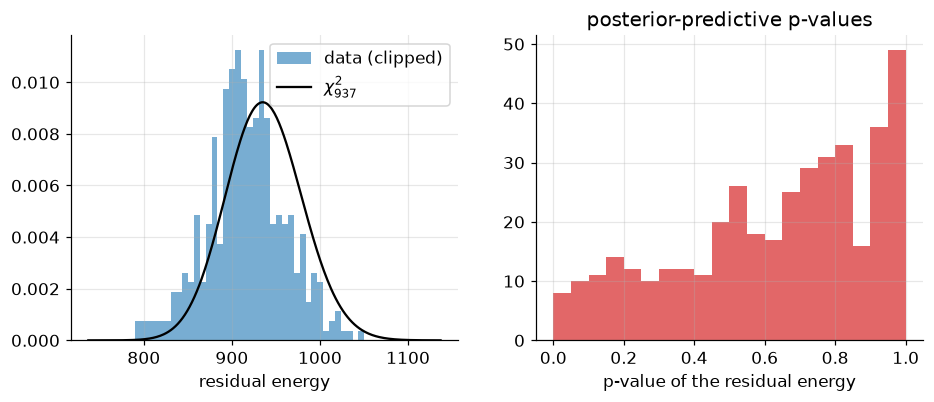

{'frac_p_below_0p01': 0.0025, 'frac_p_below_0p05': 0.02, 'median_p': 0.6867035193787835}
expected median p-value 0.5; the in-band noise variance is 1.975 (not 2) per real component, which lowers the residual energy slightly


In [13]:
n = 400
S1 = CH[3]["S1"]; base = v_te[id_te == 3][rng.choice((id_te == 3).sum(), n, replace=False)]
ser, p, _ = g.inject(base, "sg", 10.0, rng, S1)
X = g.to_bins(ser); o = FB[3].scan(X, tau_range=TAU_RANGE, batch=16)
resE = np.zeros(n)
for i in range(n):
    T = template(o["f0"][i], o["Q"][i], o["tau"][i], S1); a = np.sum(X[i] * np.conj(T))
    resE[i] = np.sum(np.abs(X[i] - a * T)**2)
dof = 2 * g.NBAND - 5
pv = stats.chi2.sf(resE, dof)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(resE, bins=60, range=(dof - 200, dof + 200), density=True, color=g.COLORS["freq"], alpha=.6, label="data (clipped)")
xs = np.linspace(dof - 200, dof + 200, 300); ax[0].plot(xs, stats.chi2.pdf(xs, dof), "k", label=rf"$\chi^2_{{{dof}}}$"); ax[0].legend(); ax[0].set_xlabel("residual energy")
ax[1].hist(pv, bins=20, range=(0, 1), color=g.COLORS["bayes"], alpha=.7); ax[1].set_xlabel("p-value of the residual energy"); ax[1].set_title("posterior-predictive p-values")
g.savefig(fig, "fig04_ppc"); plt.show()
ppc = dict(frac_p_below_0p01=float((pv < .01).mean()), frac_p_below_0p05=float((pv < .05).mean()), median_p=float(np.median(pv)))
print(ppc); summary["ppc"] = ppc
print("expected median p-value 0.5; the in-band noise variance is 1.975 (not 2) per real component, which lowers the residual energy slightly")

## 7. Credible against confidence intervals at low SNR

The simplest setting where Bayesian and frequentist intervals can be compared exactly: a **known template** and the unknown SNR $s\ge0$ measured through $\hat s=|z|$ (Rice). The posterior is
$p(s|\hat s)\propto\pi(s)\,e^{-s^2/2}I_0(s\hat s)$. We compute the **frequentist coverage** of the 68 % credible intervals (central and HPD) for a flat prior on $s\ge0$ and for the project's Rayleigh($\sigma_\rho=10$) prior,
by integrating the Rice density exactly, and compare with the profile-likelihood interval and the Neyman / Feldman–Cousins belts of notebook 03.

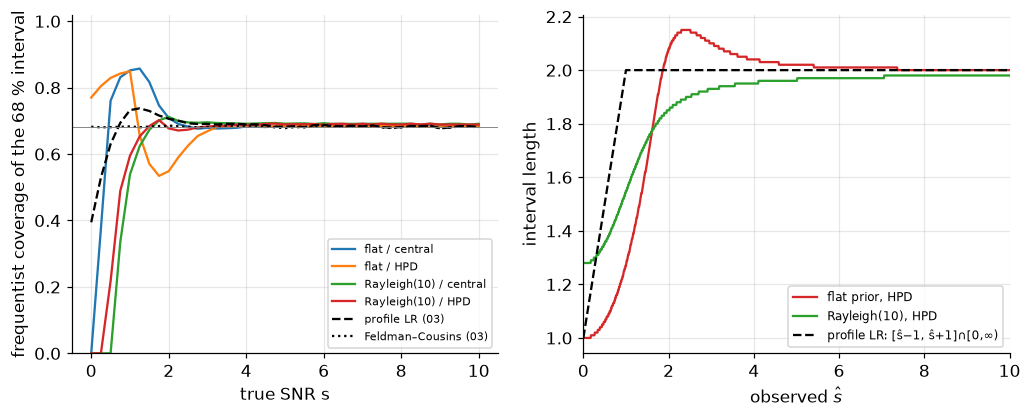

,flat / central,flat / HPD,Rayleigh(10) / central,Rayleigh(10) / HPD
0.00,0.000000,0.770209,0.000000,0.000000
1.25,0.857356,0.656948,0.623677,0.652957
2.50,0.682622,0.625494,0.695333,0.673563
3.75,0.679094,0.686593,0.692151,0.688558
5.00,0.682706,0.685156,0.691388,0.689379
6.25,0.685801,0.683383,0.690610,0.690610
7.50,0.684852,0.684852,0.691287,0.691287
8.75,0.684276,0.681849,0.691306,0.691306
10.00,0.686318,0.683898,0.691109,0.688714


In [14]:
sg_ = np.linspace(0, 40, 4001); xg = np.linspace(0, 25, 2501)
rice = lambda x, s: x * special.i0e(x * s) * np.exp(-(x - s)**2 / 2)
priors = {"flat": np.ones_like(sg_), "Rayleigh(10)": sg_ * np.exp(-sg_**2 / 200)}
def cred_intervals(prior, hpd):
    lo, hi = np.zeros(len(xg)), np.zeros(len(xg))
    for i, x in enumerate(xg):
        post = prior * special.i0e(sg_ * x) * np.exp(-(sg_ - x)**2 / 2)
        lo[i], hi[i] = interval(sg_, post, 0.6827, hpd=hpd)
    return lo, hi
S_GRID = np.linspace(0, 10, 41); dx = xg[1] - xg[0]
cov = {}
for pn, pr in priors.items():
    for hpd in (False, True):
        lo, hi = cred_intervals(pr, hpd)
        cov[f"{pn} / {'HPD' if hpd else 'central'}"] = [float((rice(xg, s) * ((lo <= s) & (s <= hi))).sum() * dx) for s in S_GRID]
f3 = pd.DataFrame(g.load_json("03_summary.json")["toy_amplitude"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, v in cov.items(): ax[0].plot(S_GRID, v, label=k)
ax[0].plot(f3.s, f3.cov_profile, "k--", label="profile LR (03)"); ax[0].plot(f3.s, f3.cov_fc, "k:", label="Feldman–Cousins (03)")
ax[0].axhline(0.6827, color="grey", lw=.6); ax[0].set_ylim(0, 1.02); ax[0].set_xlabel("true SNR s"); ax[0].set_ylabel("frequentist coverage of the 68 % interval"); ax[0].legend(fontsize=7.5)
# length of the intervals: 'information' provided at low SNR
lo_f, hi_f = cred_intervals(priors["flat"], True)
ax[1].plot(xg, hi_f - lo_f, color=g.COLORS["bayes"], label="flat prior, HPD")
lo_r, hi_r = cred_intervals(priors["Rayleigh(10)"], True); ax[1].plot(xg, hi_r - lo_r, color=g.COLORS["ml"], label="Rayleigh(10), HPD")
ax[1].plot(xg, np.where(xg > 1, 2.0, xg + 1.0), "k--", label="profile LR: [ŝ−1, ŝ+1]∩[0,∞)")
ax[1].set_xlim(0, 10); ax[1].set_xlabel(r"observed $\hat s$"); ax[1].set_ylabel("interval length"); ax[1].legend(fontsize=8)
g.savefig(fig, "fig04_credible_vs_confidence"); plt.show()
summary["coverage_credible"] = dict(s=S_GRID, **cov)
pd.DataFrame(cov, index=np.round(S_GRID, 2)).iloc[::5]

For $s\gtrsim3$ credible and confidence intervals coincide at 68–69 % (Bernstein–von Mises: the posterior becomes Gaussian and the prior irrelevant). Below that they diverge, in a way that is instructive rather than embarrassing: credible intervals are **conditional on the observed data** and make no coverage promise.
With a flat prior the 68 % central interval has *zero* coverage at $s=0$ (the lower limit is always above 0), the HPD interval covers 77 % at $s=0$ and 85 % at $s\approx1$ and then dips to 53 % at $s\approx1.7$; with the Rayleigh(10) prior both under-cover for $s\lesssim1.5$ (54–60 % at $s=1$) because the prior favours larger SNRs than the truth.
The Neyman/Feldman–Cousins intervals cover by construction and the profile-likelihood interval of notebook 03 sits in between (39 % at $s=0$, 74 % at $s=1$); the interval *length* of the HPD intervals is shorter than the profile one at $\hat s\lesssim2$ (1.0–1.9 against 1–2) — the usual trade between informativeness and guaranteed coverage.

## Summary

In [15]:
summary["mcmc_vs_grid"] = mcmc_tab.to_dict("records")
summary["posterior_examples"] = rows if False else None
g.save_json(summary, "04_summary.json")
print("saved; keys:", list(summary))

saved; keys: ['closed_form_check', 'noise_false_evidence', 'bf_vs_freq', 'prior_dependence_median_lnBF', 'sbc', 'ppc', 'coverage_credible', 'mcmc_vs_grid', 'posterior_examples']


## Output and next step

* `results/04_summary.json`, `figures/fig04_*`; scans cached in `cache/scan04_*.npz`.

Next: **`05_ml_detection.ipynb`** — supervised and unsupervised machine-learning detectors (features + linear/tree models, 1-D CNN, autoencoder), calibrated against the same background and compared with the matched filter.